<a href="https://colab.research.google.com/github/nguyenkyvi/Machine_Learning/blob/main/Lab06_SVM/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
# -*- coding: utf-8 -*-
"""Bước 1: tìm đường có lề rộng nhất và các vecto hỗ trợ.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 24 điểm, hai cụm tách hẳn nhau
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
            cluster_std=0.9, random_state=0)
y = 1 - y   # Lớp 1 là cụm dưới bên trái, giống hình trên slide

# C rất lớn nghĩa là không cho điểm nào nằm trong lề
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.3f}")
print()

# Các vectơ hỗ trợ nằm đúng trên hai mép lề, nơi f(x) bằng 1 hoặc -1
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f}, "
          f"lop {y[i]}, f(x) = {f:+.3f}")
print()

# Những điểm khác nằm ngoài lề, nên |f(x)| lớn hơn 1
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()

# Học lại chỉ với các vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f" w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()

# Dự đoán cho hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi),
                           svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.213

So vecto ho tro: 3
diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
 w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


In [30]:
# -*- coding: utf-8 -*-
"""Bước 2: lề mềm, tham số C, và vì sao SVM phải chuẩn hoá."""

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("   C    so vecto HT   do rong le   tap hoc   tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]  # bước cuối của pipeline là SVM
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {C:4}   {len(svm.support_):6}      {le:6.2f}     {a_hoc:.4f}    {a_kt:.4f}")

print()

# Bộ sinh viên mở rộng có thêm cột chi tiêu, tính bằng nghìn đồng
df3 = pd.read_csv("data/sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)

tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"Doan bua ca lop qua : {y3_te.mean():.4f}")
print(
    "Khong chuan hoa    : "
    f"{accuracy_score(y3_te, tho.predict(X3_te)):.4f}"
)
print(
    "Co chuan hoa       : "
    f"{accuracy_score(y3_te, chuan.predict(X3_te)):.4f}"
)

Tap hoc co 90 ban
   C    so vecto HT   do rong le   tap hoc   tap kiem tra
  0.01       74        3.84     0.8556    0.8667
   0.1       44        1.70     0.8889    0.9000
     1       31        1.29     0.8778    0.9000
    10       28        1.06     0.9000    0.9000
   100       27        1.05     0.9000    0.9000

Ba cot, kernel RBF mac dinh
Doan bua ca lop qua : 0.6000
Khong chuan hoa    : 0.6000
Co chuan hoa       : 0.9000


In [31]:
# -*- coding: utf-8 -*-
"""Phần 1 và Phần 2: Kernel SVM, nâng chiều dữ liệu."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Phần 1: dữ liệu một chiều, Lớp 1 nằm giữa, Lớp 0 ở hai đầu
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)

# Thử mọi ngưỡng: đoán Lớp 1 khi x nhỏ hơn hoặc bằng ngưỡng
tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

# Thêm cột bình phương rồi dùng SVM tuyến tính
X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Phần 2: hai văng trăng, để kernel tự nâng chiều
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}

print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:26s} {acc:.4f}")
print()

rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_),
      "tren", len(X_tr), "diem hoc")

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000

Hai vang trang, accuracy tren tap kiem tra
 SVM kernel tuyen tinh      0.8667
 SVM kernel da thuc bac 3   0.8667
 SVM kernel RBF             0.9200
 Hoi quy logistic           0.8533
 KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


In [32]:
# -*- coding: utf-8 -*-
"""Bước 4: ảnh hưởng của gamma, rồi dò lưới C và gamma."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma   tap hoc   tap kiem tra   so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {g:5}   {a_hoc:.4f}      {a_kt:.4f}         {len(mh.support_)}")

print()

# Dò Lưới: thử mọi cặp bằng kiểm định chéo 5 phần, chỉ trên tập học
luoi = {"C": [0.01, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()

print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
# GridSearchCV đã tự học lại với cặp tốt nhất trên toàn tập học
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

gamma   tap hoc   tap kiem tra   so vecto HT
   0.1   0.8356      0.8533         113
     1   0.8711      0.9200         88
    10   0.8978      0.9067         128
   100   0.9422      0.8133         217

Diem kiem dinh cheo, hang la C, cot la gamma
gamma    0.01    0.10    1.00    10.00
C                                     
0.01    0.6578  0.6578  0.6800  0.7200
1.00    0.8044  0.8178  0.8667  0.8667
10.00   0.8178  0.8400  0.8711  0.8311
100.00  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


In [33]:
# -*- coding: utf-8 -*-
"""Bước 5 Phần nhận dạng chữ số viết tay bằng SVM, KNN và Logistic Regression."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()

# So với các mô hình đã học
mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)
    ),
}
print("Cac mo hình khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:22s} {acc:.4f}")

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hình khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778
  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


BÀI TẬP


Bài 1. Tính tay khoảng cách tới ranh giới

In [34]:
import numpy as np

# Giả sử w và b đã được lấy từ mô hình SVC ở mục trước (ví dụ từ bước 1 hoặc 2)
# w = svm.coef_[0]  => w[0], w[1]
# b = svm.intercept_[0]

# Tạm gán giá trị w và b mẫu (bạn thay bằng w, b thực tế từ mô hình của bạn):
# w1, w2, b = 1.234, 2.345, -0.500
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)

diem_moi = [np.array([3.0, 3.0]), np.array([5.0, 4.5])]
for diem in diem_moi:
    # Tính f(x) bằng phép nhân và cộng: w1*x1 + w2*x2 + b
    f_tay = w[0] * diem[0] + w[1] * diem[1] + b
    khoang_cach = np.abs(f_tay) / do_dai_w
    print(
        f"Diem ({diem[0]}, {diem[1]}): f(x) = {f_tay:+.3f}, Khoang cach ="
        f" {khoang_cach:.4f}"
    )

print("\nKhoang cach cua ba vecto ho tro den ranh gioi:")
for i in svm.support_:
    f_sv = w[0] * X[i, 0] + w[1] * X[i, 1] + b
    kc_sv = np.abs(f_sv) / do_dai_w
    print(
        f"Vecto ho tro {i}: f(x) = {f_sv:+.3f}, Khoang cach = {kc_sv:.4f} (bang"
        f" dung mot nua do rong le: {2 / do_dai_w / 2:.4f})"
    )

Diem (3.0, 3.0): f(x) = +1.262, Khoang cach = 1.3958
Diem (5.0, 4.5): f(x) = -0.933, Khoang cach = 1.0325

Khoang cach cua ba vecto ho tro den ranh gioi:
Vecto ho tro 21: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 27: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 83: f(x) = +4.111, Khoang cach = 4.5475 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 123: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 130: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 159: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 186: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 280: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro 285: f(x) = +4.820, Khoang cach = 5.3327 (bang dung mot nua do rong le: 1.1063)
Vecto ho tro

Bài tập 2: Thêm một điểm

In [35]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# Tạo lại đúng 24 điểm dữ liệu của mục 2 (2 chiều)
X_goc, y_goc = make_blobs(
    n_samples=24, centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0
)
y_goc = 1 - y_goc

# 1. Thêm một điểm lớp 1 tại (-1, -1)
X_moi_1 = np.vstack([X_goc, np.array([[-1, -1]])])
y_moi_1 = np.append(y_goc, 1)

svm_1 = SVC(kernel="linear", C=1000).fit(X_moi_1, y_moi_1)
print("Khi them diem (-1, -1):")
print(f"w = {svm_1.coef_[0]}, b = {svm_1.intercept_[0]}")
print(f"So vecto ho tro: {len(svm_1.support_)}")
print("-" * 40)

# 2. Thay bằng một điểm lớp 1 tại (4.5, 4)
X_moi_2 = np.vstack([X_goc, np.array([[4.5, 4]])])
y_moi_2 = np.append(y_goc, 1)

svm_2 = SVC(kernel="linear", C=1000).fit(X_moi_2, y_moi_2)
print("Khi thay bang diem (4.5, 4):")
print(f"w = {svm_2.coef_[0]}, b = {svm_2.intercept_[0]}")
print(f"So vecto ho tro: {len(svm_2.support_)}")

Khi them diem (-1, -1):
w = [-0.8313573  -0.35486826], b = 4.820360900256654
So vecto ho tro: 3
----------------------------------------
Khi thay bang diem (4.5, 4):
w = [-2.60301403 -0.80684301], b = 15.940939298815394
So vecto ho tro: 2


Bài tập 3: Kernel đa thức

In [36]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X, y = df[["x1", "x2"]], df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

for d in [2, 3, 4]:
    # Sử dụng pipeline chuẩn hoá và grid search cho C (viết là 'svc__C')
    pipeline = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    luoi = {"svc__C": [0.1, 1, 10, 100]}
    tim = GridSearchCV(pipeline, luoi, cv=5)
    tim.fit(X_tr, y_tr)
    print(
        f"Degree d={d}: Best C={tim.best_params_}, Score CV={tim.best_score_:.4f},"
        f" Test Acc={tim.score(X_te, y_te):.4f}"
    )

Degree d=2: Best C={'svc__C': 1}, Score CV=0.5422, Test Acc=0.5067
Degree d=3: Best C={'svc__C': 1}, Score CV=0.8178, Test Acc=0.8267
Degree d=4: Best C={'svc__C': 100}, Score CV=0.5156, Test Acc=0.4800


Bài tập 4: Dò lưới mịn

In [37]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X, y = df[["x1", "x2"]], df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim_min = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5)
tim_min.fit(X_tr, y_tr)

print("Cap tot nhat (min):", tim_min.best_params_)
print(f"Diem kiem dinh cheo tot nhat: {tim_min.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim_min.score(X_te, y_te):.4f}")

Cap tot nhat (min): {'C': 30, 'gamma': 1}
Diem kiem dinh cheo tot nhat: 0.8756
Accuracy tren tap kiem tra: 0.9200


Bài tập 5: Chữ số viết tay, những lỗi nào hay gặp

Bang nham lan (Confusion Matrix):
 [[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 44  0  0  0  1  0]
 [ 0  0  0  0  0 46  0  0  0  0]
 [ 0  0  0  0  0  0 45  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  0  0  0 42  0]
 [ 0  0  0  1  0  0  0  0  0 44]]


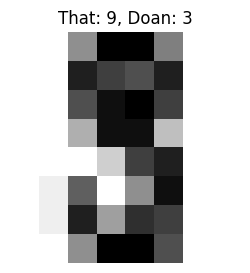

In [38]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

# In bảng nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_te, du_doan)
print("Bang nham lan (Confusion Matrix):\n", cm)

# Tìm và vẽ một ảnh bị đoán sai
sai = np.flatnonzero(du_doan != y_te)
if len(sai) > 0:
    i = sai[0]
    plt.figure(figsize=(3, 3))
    plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    plt.title(f"That: {y_te[i]}, Doan: {du_doan[i]}")
    plt.axis("off")
    plt.show()

Bài tập 6: SVM trên dữ liệu lớn

In [39]:
import time
from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC

for n in [2000, 5000, 10000, 20000]:
    X, y = make_classification(
        n_samples=n, n_features=20, random_state=0
    )

    # Đo thời gian cho LinearSVC
    t0 = time.time()
    LinearSVC(dual=False, random_state=0).fit(X, y)
    t_linear = time.time() - t0

    # Đo thời gian cho SVC tuyến tính (hoặc mặc định)
    t0 = time.time()
    SVC(kernel="linear").fit(X, y)
    t_svc = time.time() - t0

    print(
        f"n = {n:5d} | LinearSVC: {t_linear:.4f}s | SVC(kernel='linear'):"
        f" {t_svc:.4f}s"
    )

n =  2000 | LinearSVC: 0.0101s | SVC(kernel='linear'): 0.0810s
n =  5000 | LinearSVC: 0.0230s | SVC(kernel='linear'): 0.8934s
n = 10000 | LinearSVC: 0.0308s | SVC(kernel='linear'): 10.1173s
n = 20000 | LinearSVC: 0.0719s | SVC(kernel='linear'): 31.7211s
